In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path
import scipy.io
import matplotlib.pyplot as plt
import anndata as ad
import shutil

In [6]:
def construct_anndata_norVelo(file_path):
    
    barcodes = pd.read_csv(file_path / 'barcodes.tsv.gz', header=None)
    features = pd.read_csv(file_path / 'features.tsv.gz', header=None, sep="\t")
    mtx = scipy.io.mmread(file_path / 'matrix.mtx.gz').tocsc()
    
    adata = ad.AnnData(X=mtx.T, dtype='float32')
    
    # barcodes
    adata.obs['barcodes'] = barcodes[0].values
    adata.obs_names = adata.obs['barcodes']
    # features
    adata.var['features'] = features[1].values
    adata.var_names = adata.var['features']
    
    adata.layers['counts'] = adata.X.copy()
    
    return adata

def pre_processing(adata):
    # filter gene expressed proportion is  less than 0.1% in all cell
    # sc.pp.filter_genes(adata, min_cells=0.001*len(adata.obs))
    
    adata.var['mt'] = adata.var_names.str.startswith('MT-')
    adata.var['rb'] = adata.var_names.str.contains('^RP[SL]')
    adata.var['hb'] = adata.var_names.str.contains('^HB[APS]')
    adata.var['hsp'] = adata.var_names.str.contains('^HSP')
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rb','hb','hsp'], percent_top=None, log1p=False, inplace=True)
    
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=1)
    
    adata = adata[adata.obs.total_counts > 300, :]
    adata = adata[adata.obs.total_counts < 30000, :]
    adata = adata[adata.obs.pct_counts_mt < 10, :]
    adata = adata[adata.obs.pct_counts_hb < 5, :]
    
    return adata

In [7]:
data_path = Path('/data/work/GZ_lab/ovarian/data/GSE269942/')

adatas = []
batch_keys = []

for data_dir in data_path.iterdir():
    if data_dir.is_dir():
        batch_keys.append(data_dir.name)
        
        adata = construct_anndata_norVelo(data_dir)
        adatas.append(adata)
        print(f'{data_dir.name} has finished')

/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


GSM8330740 has finished


/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


GSM8330738 has finished


/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


...

/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


GSM8330744 has finished


/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


GSM8330743 has finished
GSM8330737 has finished


/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


In [8]:
for batch, adata in zip(batch_keys, adatas):
    adata.obs_names = [f"{barcode}_{batch}" for barcode in adata.obs_names]

In [9]:
for batch, adata in zip(batch_keys, adatas):
    adata.obs_names_make_unique()
for batch, adata in zip(batch_keys, adatas):
    adata.var_names_make_unique()

In [10]:
adata_1 = sc.concat(adatas, label='batch', keys=batch_keys)

In [3]:
adata_2 = pd.read_csv('./data/GSE281740/GSE281740_sclc_cellranger.csv')
adata_2.shape

(33538, 58070)

In [ ]:
adata_2.set_index('feature_name', inplace=True)
adata_2 = ad.AnnData(X=adata_2.T, dtype='float32')

/usr/local/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


In [42]:
adata_2.obs['batch'] = adata_2.obs_names.str.split('-').str[2]
adata_2.layers['counts'] = adata_2.X.copy()

In [43]:
adata_2.obs

,batch
AAACCCAGTACGACTT-1-Ru1124A,Ru1124A
AAACCCATCTGGAAGG-1-Ru1124A,Ru1124A
AAACGAAAGACCTCAT-1-Ru1124A,Ru1124A
AAACGCTCATTGACTG-1-Ru1124A,Ru1124A
AAAGAACAGGCCCAAA-1-Ru1124A,Ru1124A
...,...
TTTGGAGCACAAGGTG-1-Ru1449A,Ru1449A
TTTGGAGGTCAAATCC-1-Ru1449A,Ru1449A
TTTGGTTTCTGTCGTC-1-Ru1449A,Ru1449A
TTTGTTGAGTGCCTCG-1-Ru1449A,Ru1449A


In [25]:
adata_1

AnnData object with n_obs × n_vars = 22615 × 36601
    obs: 'barcodes', 'batch'
    layers: 'counts'

In [44]:
adata = sc.concat([adata_1, adata_2], label='cancer_type', keys=['Large', 'Small'])

In [45]:
adata

AnnData object with n_obs × n_vars = 80684 × 31915
    obs: 'batch', 'cancer_type'
    layers: 'counts'

In [46]:
adata = pre_processing(adata)

In [47]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

/usr/local/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [48]:
adata

AnnData object with n_obs × n_vars = 43357 × 30126
    obs: 'batch', 'cancer_type', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'
    layers: 'counts'

In [49]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    flavor="cell_ranger",
    batch_key="batch",
    #span = 0.8 # prevent minimal span result to a error
)

In [50]:
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt", 'n_genes_by_counts'], n_jobs=8)

/usr/local/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [51]:
sc.pp.pca(adata, svd_solver="arpack")

In [52]:
sc.external.pp.harmony_integrate(adata, key='batch')

2025-12-09 16:30:15,577 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-12-09 16:30:39,553 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-12-09 16:30:39,821 - harmonypy - INFO - Iteration 1 of 10
2025-12-09 16:31:01,149 - harmonypy - INFO - Iteration 2 of 10
2025-12-09 16:31:24,018 - harmonypy - INFO - Iteration 3 of 10
2025-12-09 16:31:47,150 - harmonypy - INFO - Iteration 4 of 10
2025-12-09 16:32:07,288 - harmonypy - INFO - Iteration 5 of 10
2025-12-09 16:32:27,988 - harmonypy - INFO - Converged after 5 iterations


In [53]:
sc.pp.neighbors(adata, n_neighbors=10, use_rep="X_pca_harmony", random_state=0)

In [ ]:
sc.tl.leiden(adata, resolution = 0.3, flavor = 'igraph', n_iterations=-1)
sc.tl.umap(adata, min_dist=0.3)

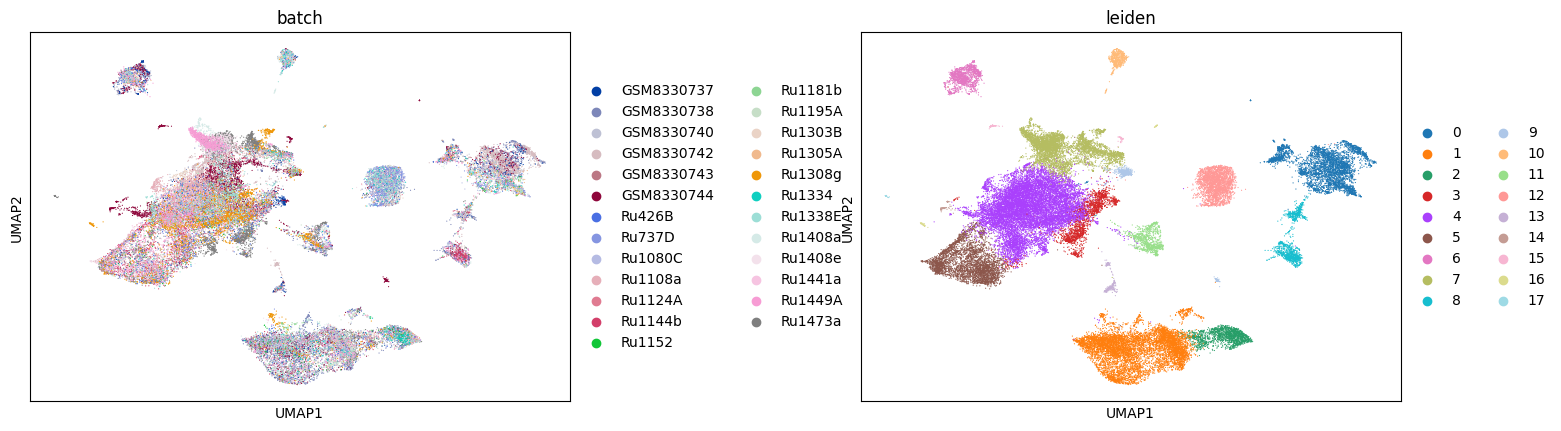

In [ ]:
sc.pl.umap(adata, color=['batch', 'leiden'], wspace=0.4)

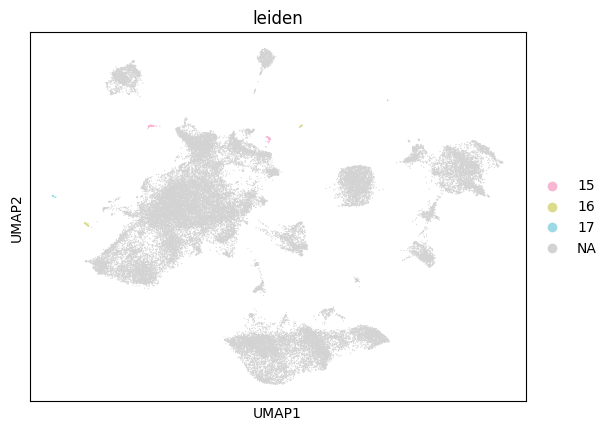

In [61]:
sc.pl.umap(adata, color=['leiden'], groups=['15', '16', '17'])

In [ ]:
sc.tl.rank_genes_groups(adata, "leiden", mask_var="highly_variable", method="wilcoxon")

In [58]:
dfs = []
for g in adata.obs["leiden"].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, group=g)
    df["cluster"] = g
    dfs.append(df)
markers = pd.concat(dfs, ignore_index=True)

marker_df = markers.assign(row_index=markers.groupby('cluster').cumcount()).pivot_table(index='row_index', columns='cluster', values='names',  aggfunc='first')
marker_df.index.name = None
marker_df.columns.name = None
marker_df.loc[1:100].to_csv('04_publicData_marker.csv')

In [62]:
adata = adata[~adata.obs['leiden'].isin(['15', '16', '17'])].copy()
adata

AnnData object with n_obs × n_vars = 43176 × 30126
    obs: 'batch', 'cancer_type', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'leiden'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap', 'batch_colors', 'leiden_colors', 'rank_genes_groups', 'cancer_type_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [ ]:
anno_mapping = {
    "0": "Macrophage",
    "1": "T cell",
    "2": "NK cell",
    "3": "Epi_1",
    "4": "Epi_2",
    "5": "Epi_3",
    "6": "Fibroblast",
    "7": "Epi_4",
    "8": "B cell",
    "9": "Epi_5",
    "10": "Endothelial cell",
    "11": "Plasma cell",
    '12': "Monocyte",
    "13": "Mast cell",
    "14": "Mast cell"
}

adata.obs['anno_I'] = adata.obs['leiden'].replace(anno_mapping)

In [ ]:
adata.write_h5ad('./data/public_with_anno.h5ad')

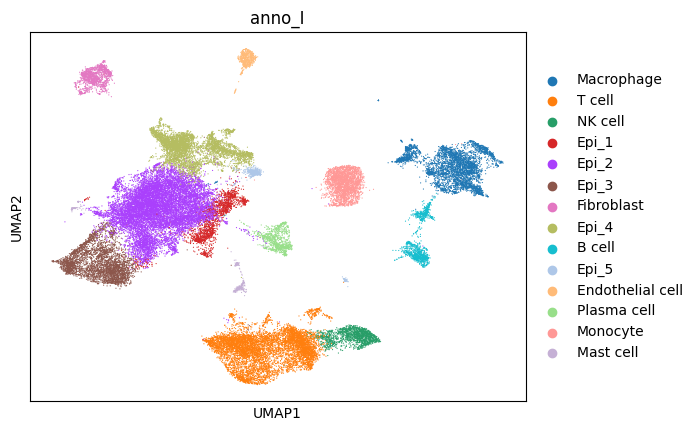

In [65]:
sc.pl.umap(adata, color='anno_I')

In [ ]:
# plot

In [9]:
func_marker_dict = {
    "Classic": ['SYP', 'CHGA', 'CHGB', 'CALCA', 'CALCB', 'ENO2', 'NCAM1'],
    "Somatostain": ['SSTR1', 'SSTR2', 'SSTR3'],
    "TF": ['ASCL1', 'ASCL2', 'POU2F3', 'YAP1', 'FOXA2', 'TFF3']
}

In [67]:
adata

AnnData object with n_obs × n_vars = 43176 × 30126
    obs: 'batch', 'cancer_type', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap', 'batch_colors', 'leiden_colors', 'rank_genes_groups', 'cancer_type_colors', 'anno_I_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [7]:
adata.obs['plot_type'] = adata.obs['cancer_type'].astype(str) + '_' + adata.obs['anno_I'].astype(str)

In [11]:
adata.obs['plot_type'].unique()

['Large_Epi_1', 'Large_Epi_2', 'Large_Epi_4', 'Large_Epi_5', 'Large_Epi_3', 'Small_Epi_3', 'Small_Epi_2', 'Small_Epi_4', 'Small_Epi_1', 'Small_Epi_5']
Categories (10, object): ['Large_Epi_1', 'Large_Epi_2', 'Large_Epi_3', 'Large_Epi_4', ..., 'Small_Epi_2', 'Small_Epi_3', 'Small_Epi_4', 'Small_Epi_5']

In [12]:
cell_order = ['Large_Epi_1', 'Small_Epi_1',
              'Large_Epi_2', 'Small_Epi_2',
              'Large_Epi_3', 'Small_Epi_3',
              'Large_Epi_4', 'Small_Epi_4',
              'Large_Epi_5', 'Small_Epi_5']
adata.obs['plot_type'] = (
    pd.Categorical(adata.obs['plot_type'],
                  categories=cell_order,
                  ordered=True)
)

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
font_dir = '/data/work/GZ_lab/ovarian/font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

custom_colors = ["#57C3F3", "white", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)


dp = sc.pl.dotplot(
    adata,
    func_marker_dict,
    'plot_type',
    dendrogram=False,
    standard_scale='var',
    cmap=cmap_custom,
    var_group_rotation=0,
    return_fig=True,
    show=False
)

# 2️⃣ 创建图像
dp.make_figure()
fig = dp.fig 
# 3️⃣ 删除横向 colorbar
for a in fig.axes:
    if a.get_position().x0 > 0.9:  # 通常 colorbar 在最右侧
        fig.delaxes(a)

fig.savefig('./fig/fig4_func_marker_expression.pdf', format='pdf', bbox_inches='tight')
plt.show()

NameError: name 'sc' is not defined

In [69]:
df = pd.crosstab(adata.obs['batch'], adata.obs['anno_I']).div(pd.crosstab(adata.obs['batch'], adata.obs['anno_I']).sum(axis=1), axis=0)

In [70]:
df

anno_I,Macrophage,T cell,NK cell,Epi_1,Epi_2,Epi_3,Fibroblast,Epi_4,B cell,Epi_5,Endothelial cell,Plasma cell,Monocyte,Mast cell
batch,,,,,,,,,,,,,,
GSM8330737,0.140251,0.189282,0.075257,0.110604,0.139111,0.050171,0.119726,0.046750,0.010262,0.001140,0.052452,0.017104,0.020525,0.027366
GSM8330738,0.132533,0.454970,0.057816,0.011119,0.018012,0.010229,0.022015,0.016678,0.082499,0.000222,0.006893,0.021792,0.151879,0.013342
GSM8330740,0.174691,0.257221,0.012380,0.060523,0.030261,0.001376,0.319120,0.101788,0.004127,0.012380,0.017882,0.001376,0.005502,0.001376
GSM8330742,0.437211,0.067746,0.018506,0.014871,0.086252,0.007931,0.014210,0.130205,0.048249,0.005948,0.001652,0.002974,0.124587,0.039656
GSM8330743,0.150327,0.104575,0.006536,0.049020,0.300654,0.202614,0.009804,0.120915,0.000000,0.016340,0.029412,0.003268,0.000000,0.006536
GSM8330744,0.065879,0.152756,0.012861,0.031496,0.445669,0.012598,0.053806,0.104199,0.016798,0.066404,0.004199,0.008399,0.002362,0.022572
Ru426B,0.052685,0.117528,0.033435,0.088146,0.368794,0.121581,0.085106,0.031408,0.013171,0.007092,0.032421,0.042553,0.003040,0.003040
Ru737D,0.117526,0.165636,0.083162,0.006186,0.098969,0.028179,0.009622,0.013746,0.014433,0.004811,0.013058,0.001375,0.439175,0.004124
Ru1080C,0.143032,0.222494,0.025672,0.061125,0.249389,0.152812,0.007335,0.040342,0.051345,0.006112,0.009780,0.013447,0.017115,0.000000


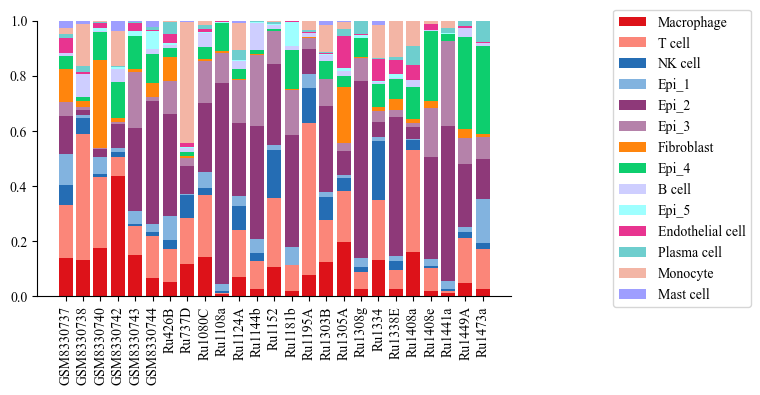

In [74]:
fig, ax = plt.subplots(figsize=(8, 4))

celltype2color = {
    'Macrophage': '#DC050C',
    'T cell': '#FB8072',
    'NK cell': '#1965B0',
    'Epi_1': '#7BAFDE',
    'Epi_2': '#882E72',
    'Epi_3': '#B17BA6',
    'Fibroblast': '#FF7F00',
    'Epi_4': '#00CC66',
    'Epi_5': '#99FFFF',
    'Endothelial cell': '#E7298A',
    'Plasma cell': '#66CCCC',
    'Monocyte': '#F3B1A0',
    'Mast cell': '#9999FF',
    'B cell': '#CCCCFF'
}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=celltype2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="", loc='center left', bbox_to_anchor=(1.2, 0.5))
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("./fig/fig4_sample_celltype_ratio.pdf", format='pdf')
plt.show()

In [80]:
df = pd.crosstab(adata.obs['anno_I'], adata.obs['cancer_type']).div(pd.crosstab(adata.obs['anno_I'], adata.obs['cancer_type']).sum(axis=1), axis=0)
df

cancer_type,Large,Small
anno_I,,
Macrophage,0.596517,0.403483
T cell,0.430444,0.569556
NK cell,0.275047,0.724953
Epi_1,0.208076,0.791924
Epi_2,0.181152,0.818848
Epi_3,0.062500,0.937500
Fibroblast,0.553140,0.446860
Epi_4,0.216182,0.783818
B cell,0.496234,0.503766


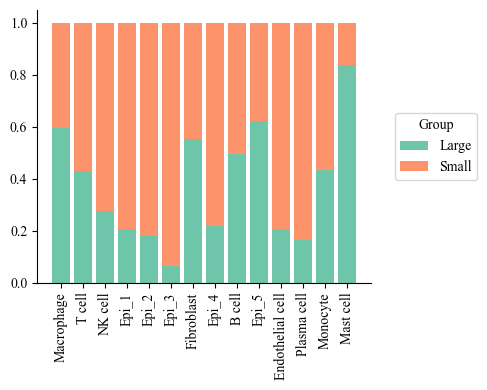

In [81]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.set_palette('Set2')

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95)
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()
labels = ['normal' if l == 'non-cancer' else l for l in labels]

legend = ax.legend(handles, labels,
    title = 'Group',
    loc ='center left',
    bbox_to_anchor=(1.05, 0.5),
    frameon = True)
                   
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("./fig/fig4_sample_ratio.pdf", format='pdf')
plt.show()

# SCENIC

In [57]:
import scanpy as sc
import pandas as pd
import pickle
import glob
import os
import numpy as np
from scipy.stats import zscore
import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

from dask.diagnostics import ProgressBar

from pyscenic.utils import modules_from_adjacencies, load_motifs
from pyscenic.prune import prune2df, df2regulons
from pyscenic.aucell import aucell
from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from arboreto.algo import grnboost2
from arboreto.utils import load_tf_names
from pyscenic.plotting import plot_rss


from matplotlib.colors import to_rgba
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind

import matplotlib.font_manager as fm
font_dir = '/data/work/GZ_lab/ovarian/font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

In [3]:
adata = sc.read_h5ad('./data/public_with_anno.h5ad')

In [4]:
adata = adata[adata.obs['anno_I'].str.startswith('Epi')].copy()

In [5]:
sc.pp.filter_genes(adata, min_cells=1)
adata

AnnData object with n_obs × n_vars = 23118 × 29048
    obs: 'batch', 'cancer_type', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'batch_colors', 'cancer_type_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [6]:
f_tfs = './allTFs_hg38.txt'
f_tfs = load_tf_names(f_tfs)

In [18]:
from distributed import Client, LocalCluster

cluster = LocalCluster(
    n_workers=10,
    threads_per_worker=4,
    memory_limit='32GB'
)
client = Client(cluster)
print(client)

/opt/software/python/lib/python3.8/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 37067 instead
  warnings.warn(


<Client: 'tcp://127.0.0.1:46089' processes=10 threads=40, memory=298.02 GiB>


In [19]:
expr_matrix = adata.to_df()
gene_var = expr_matrix.var(axis=0)
top_genes = gene_var.sort_values(ascending=False).head(10000).index.tolist()
expr_small = expr_matrix[top_genes]

In [20]:
expr_small.shape

(23118, 10000)

In [21]:
adjacencies = grnboost2(
    expr_small,
    tf_names=f_tfs,
    client_or_address=client,
    verbose=True
)

preparing dask client
parsing input
creating dask graph
10 partitions
computing dask graph


/opt/software/python/lib/python3.8/site-packages/distributed/client.py:3108: UserWarning: Sending large graph of size 1.73 GiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


not shutting down client, client was created externally
finished


In [23]:
modules = list(modules_from_adjacencies(adjacencies, expr_small))


2025-12-09 23:19:25,759 - pyscenic.utils - INFO - Calculating Pearson correlations.

2025-12-09 23:19:26,029 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2025-12-09 23:19:37,899 - pyscenic.utils - INFO - Creating modules.


In [24]:
db_fnames = glob.glob('./hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather')
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]

with ProgressBar():
    df = prune2df(dbs, modules, './motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl.txt')

[                                        ] | 0% Completed | 117.33 ms

/opt/software/python/lib/python3.8/site-packages/dask/base.py:1368: UserWarning: Running on a single-machine scheduler when a distributed client is active might lead to unexpected results.
  warnings.warn(


[                                        ] | 0% Completed | 184.46 ss


2025-12-09 23:25:31,553 - pyscenic.transform - WARNING - Less than 80% of the genes in ZNF584 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 185.27 s

...

[                                        ] | 0% Completed | 247.19 s


2025-12-09 23:26:34,280 - pyscenic.transform - WARNING - Less than 80% of the genes in Regulon for TRMT1 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[                                        ] | 0% Completed | 286.84 s


2025-12-09 23:27:13,946 - pyscenic.transform - WARNING - Less than 80% of the genes in TRMT1 could be mapped to hg38_500bp_up_100bp_down_full_tx_v10_clust.genes_vs_motifs.rankings. Skipping this module.


[########################################] | 100% Completed | 531.32 s


In [ ]:
# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)
print('end')

Create regulons from a dataframe of enriched features.
Additional columns saved: []
end


In [27]:
df.to_csv('./04_public_epi_motifs.csv')
with open('./04_public_epi_regulons.p', "wb") as f:
    pickle.dump(regulons, f)

In [163]:
auc_mtx = aucell(expr_matrix, regulons, num_workers=8)

In [ ]:
auc_mtx.to_csv('./04_public_epi_aucell.csv')

In [164]:
auc_mtx = auc_mtx.loc[adata.obs.index]

In [ ]:
from pyscenic.rss import regulon_specificity_scores

In [ ]:
cell_labels = (adata.obs['anno_I'].astype(str))
rss_df = regulon_specificity_scores(auc_mtx, cell_labels)

meta NOT subset; don't know how to subset; dropped


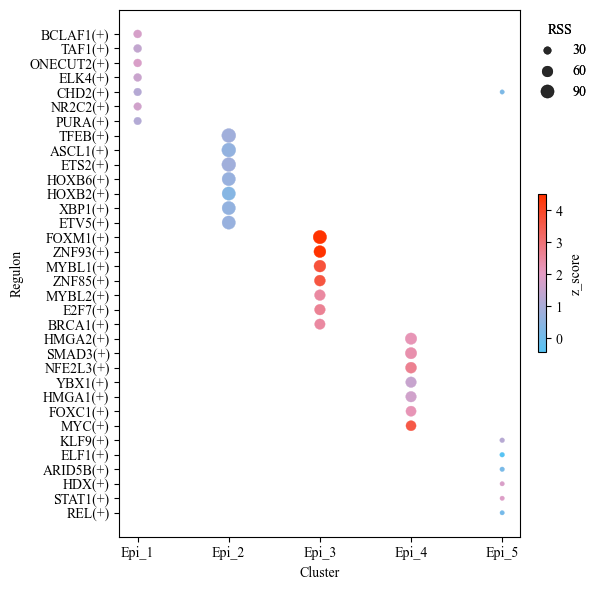

In [ ]:
rss_z = zscore(zscore(rss_df, axis=0).dropna(axis=1), axis=1)

rss_melt_df = rss_df.reset_index().melt(id_vars='index', var_name='regulon', value_name='RSS')
rss_z = rss_z.reset_index().melt(id_vars='index', var_name='regulon', value_name='z_score')
rss_melt_df = rss_melt_df.merge(rss_z, on=['index', 'regulon'], how='inner')

top_rss_df = rss_df.stack().reset_index().rename(columns={0:'RSS'}).groupby('level_0').apply(lambda x: x.nlargest(7, 'RSS')).reset_index(drop=True).rename(columns={'level_0': 'index', 'level_1': 'regulon'})
top_rss_df = top_rss_df.merge(rss_z, on=['index', 'regulon'], how='inner')

import matplotlib as mpl

plt.figure(figsize=(6, 6))

custom_colors = ["#57C3F3", "#E59CC4", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

scp = sns.scatterplot(data=top_rss_df,
                x='index', y='regulon',
                size='RSS', hue='z_score',
                sizes=(10, 100),  # 最小/最大点大小
                palette=cmap_custom, edgecolor=None)

if scp.legend_ is not None:
    scp.legend_.remove()
scatter_obj = scp.collections[0]

handles, labels = scatter_obj.legend_elements(prop="sizes", num=3, alpha=0.6)
size_legend = plt.legend(
    handles, labels,
    title="RSS",
    bbox_to_anchor=(1, 1),
    loc='upper left',
    frameon=False
)
plt.gca().add_artist(size_legend)

norm = mpl.colors.Normalize(
    vmin=top_rss_df['z_score'].min(),
    vmax=top_rss_df['z_score'].max()
)
sm = plt.cm.ScalarMappable(cmap=cmap_custom, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.05, pad=0.04, shrink=0.3)
cbar.set_label("z_score")


plt.xlabel("Cluster")
plt.ylabel("Regulon")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('./fig/fig4_tf_cnv_sepcific_top_scatter.pdf', format='pdf')
plt.show()

In [94]:
rss_df

,ARID3A(+),ARID5B(+),ARNT(+),ARNTL(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BACH1(+),BCL3(+),...,ZNF507(+),ZNF516(+),ZNF519(+),ZNF551(+),ZNF580(+),ZNF584(+),ZNF621(+),ZNF770(+),ZNF85(+),ZNF93(+)
Epi_1,0.285852,0.270337,0.272927,0.243996,0.228600,0.223874,0.255047,0.264700,0.269077,0.246068,...,0.276631,0.289221,0.292988,0.279949,0.216442,0.256406,0.275340,0.245232,0.211126,0.239521
Epi_2,0.426694,0.463213,0.418040,0.451317,0.574211,0.400733,0.522911,0.499784,0.455737,0.486565,...,0.415319,0.497582,0.449568,0.374369,0.534807,0.418118,0.352480,0.358790,0.376543,0.317299
Epi_4,0.271249,0.376123,0.282998,0.309414,0.261900,0.281020,0.308378,0.306243,0.301944,0.340271,...,0.248646,0.296458,0.248206,0.238757,0.298016,0.263573,0.263476,0.245063,0.257874,0.284227
Epi_5,0.202818,0.224226,0.202167,0.220674,0.179185,0.200624,0.188494,0.200468,0.217951,0.208612,...,0.207346,0.206315,0.196991,0.194570,0.185587,0.201881,0.216449,0.207051,0.176959,0.180213
Epi_3,0.276507,0.278168,0.258544,0.263652,0.336540,0.263587,0.303217,0.332139,0.264205,0.276496,...,0.247641,0.288089,0.351883,0.265473,0.278535,0.283679,0.248501,0.237225,0.426197,0.472746


In [64]:
def plot_significant_box(plot_df, term, condition=None):
    
    def sig_text(p):
        if p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return 'ns'
    
    if condition:
        pos_con = condition[0]
        neg_con = condition[1]
    
    condition_name = plot_df.columns[0]
    pos_info = plot_df[plot_df[condition_name] == pos_con][term]
    neg_info = plot_df[plot_df[condition_name] == neg_con][term]
    
    stat, p = mannwhitneyu(pos_info, neg_info, alternative='two-sided')
    text = sig_text(p)

    plt.figure(figsize=(3, 3))
    palette_1 = {pos_con:'#65c2ce', neg_con:'#FFB6CE'}
    palette_2 = {pos_con: '#07dbf7', neg_con: '#FA75A2'}

    ax = sns.boxplot(x=condition_name, y=term, data=plot_df, flierprops={'visible': False},
                     order=[pos_con, neg_con], palette=[to_rgba(c, alpha=0.6) for c in palette_2.values()],
                        width=0.6, linewidth=1)
    sns.stripplot(x=condition_name, y=term, data=plot_df, order=[pos_con, neg_con], palette=palette_1, size=5, alpha=0.8,
                 linewidth=1, edgecolor='black')

    ymax = plot_df[term].max()
    height = ymax.max() + ymax*0.01

    # 画横线和星号（pre vs mid）
    x1, x2 = 0, 1
    plt.plot([x1+0.1, x1+0.1, x2-0.1, x2-0.1], [height, height, height, height], lw=1.2, color='k')
    plt.text((x1+x2)/2, height+0.01, text, ha='center', va='bottom', color='k')


    plt.ylabel('Score')
    sns.despine()
    plt.tight_layout()
    plt.savefig(f'./fig/fig4_{term}_sig.pdf', format='pdf')
    plt.show()

In [162]:
sc.tl.umap(adata, min_dist=0.3, spread=1.25)

meta NOT subset; don't know how to subset; dropped


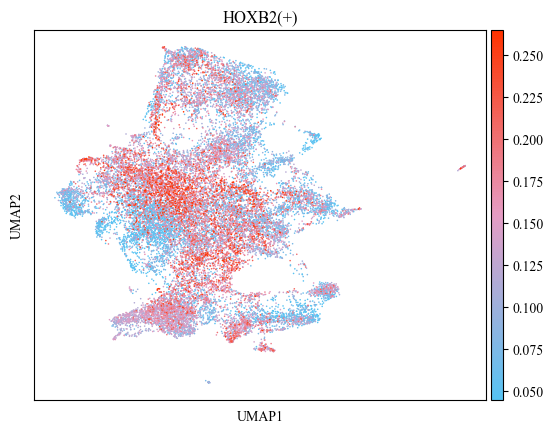

In [167]:
adata.obs['HOXB2(+)'] = auc_mtx['HOXB2(+)']
sc.pl.umap(adata, color='HOXB2(+)', vmax='p99', vmin='p15', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig4_endocrine_tf_umap.pdf', format='pdf')

/tmp/ipykernel_78/82722604.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x=condition_name, y=term, data=plot_df, flierprops={'visible': False},
/tmp/ipykernel_78/82722604.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=condition_name, y=term, data=plot_df, order=[pos_con, neg_con], palette=palette_1, size=5, alpha=0.8,
meta NOT subset; don't know how to subset; dropped


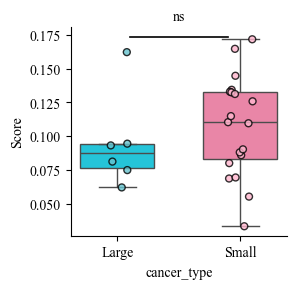

In [68]:
tmp_df = adata.obs.groupby(['cancer_type', 'batch'])['HOXB2(+)'].median().reset_index().dropna()
plot_significant_box(tmp_df, 'HOXB2(+)', condition=['Large', 'Small'])

meta NOT subset; don't know how to subset; dropped


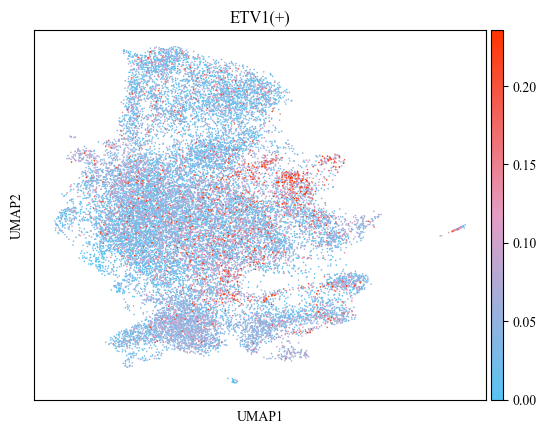

In [70]:
adata.obs['ETV1(+)'] = auc_mtx['ETV1(+)']
sc.pl.umap(adata, color='ETV1(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig4_ETV1_tf_umap.pdf', format='pdf')

/tmp/ipykernel_78/82722604.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x=condition_name, y=term, data=plot_df, flierprops={'visible': False},
/tmp/ipykernel_78/82722604.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=condition_name, y=term, data=plot_df, order=[pos_con, neg_con], palette=palette_1, size=5, alpha=0.8,
meta NOT subset; don't know how to subset; dropped


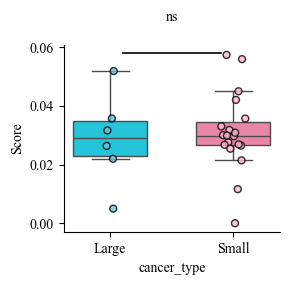

In [151]:
tmp_df = adata.obs.groupby(['cancer_type', 'batch'])['ETV1(+)'].median().reset_index().dropna()
plot_significant_box(tmp_df, 'ETV1(+)', condition=['Large', 'Small'])

meta NOT subset; don't know how to subset; dropped


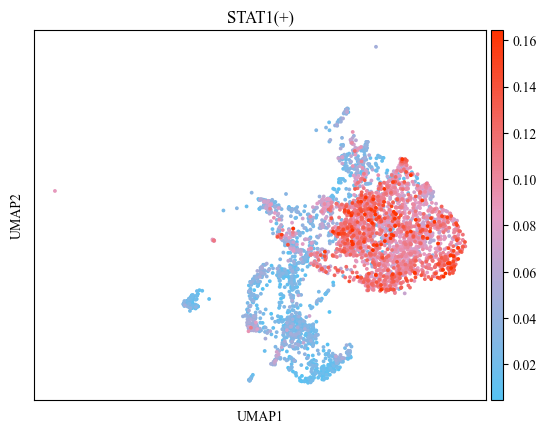

In [82]:
adata.obs['STAT1(+)'] = auc_mtx['STAT1(+)']
sc.pl.umap(adata, color='STAT1(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

plt.savefig('./fig/fig4_endocrine_STAT1_tf_umap.pdf', format='pdf')

/opt/software/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
meta NOT subset; don't know how to subset; dropped


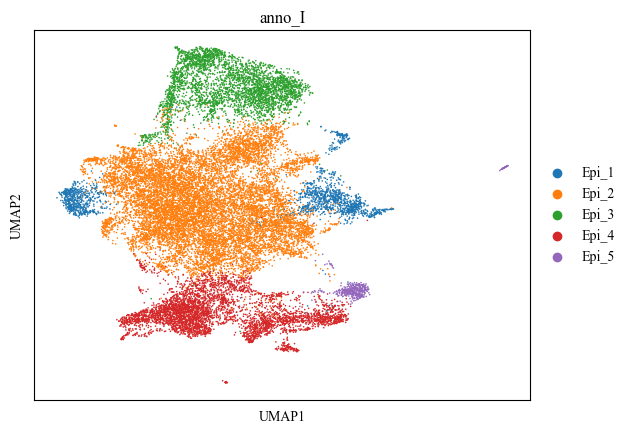

In [168]:
sc.pl.umap(adata, color='anno_I', show=False)

plt.savefig('./fig/fig4_anno_umap.pdf', format='pdf')

In [76]:
from joypy import joyplot

/tmp/ipykernel_78/3901876721.py:17: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  plt.tight_layout()
meta NOT subset; don't know how to subset; dropped


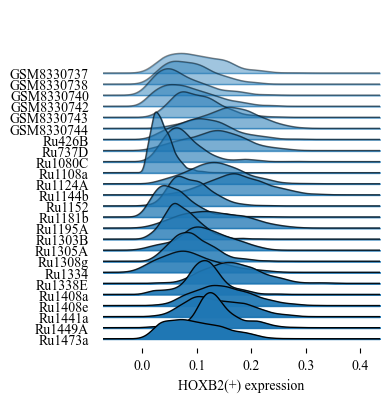

In [80]:
from matplotlib.colors import ListedColormap

plot_df = adata.obs[['batch', 'HOXB2(+)']]

batches = sorted(plot_df['batch'].unique())

joyplot(
    data=plot_df,
    by="batch",
    column="HOXB2(+)",
    linewidth=1,
    fade=True,
    figsize=(4,4)
)
plt.xlabel("HOXB2(+) expression")
#plt.title("HOXB2(+) Ridge Plot by Batch")
plt.tight_layout()
plt.savefig('./fig/fig4_sample_expression.pdf', format='pdf')
plt.show()

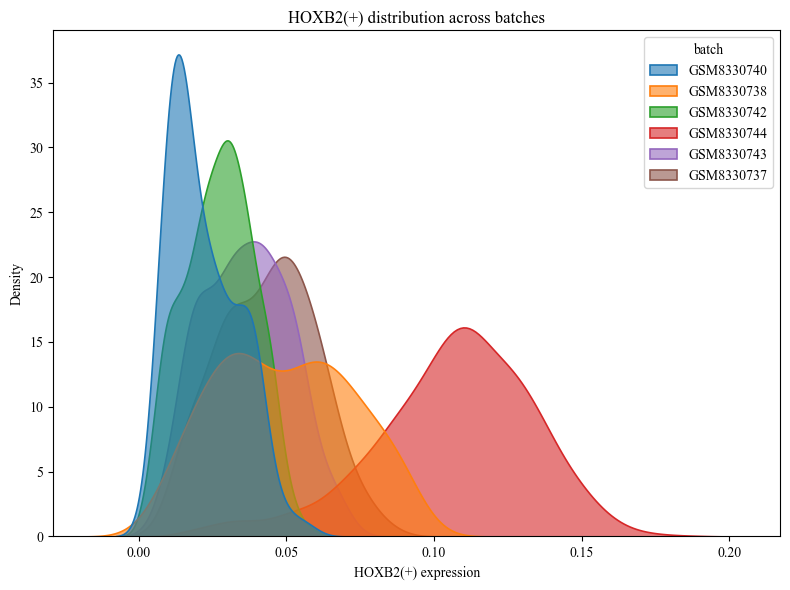

In [37]:
plt.figure(figsize=(8,6))
sns.kdeplot(
    data=plot_df,
    x="HOXB2(+)",
    hue="batch",
    fill=True,
    common_norm=False,
    alpha=0.6,
    linewidth=1.2
)
plt.xlabel("HOXB2(+) expression")
plt.ylabel("Density")
plt.title("HOXB2(+) distribution across batches")
plt.tight_layout()
plt.show()

In [81]:
import pandas as pd
import numpy as np

In [82]:
data = pd.read_csv('./03_ovarian_cancer_epi_motifs.csv', header=1)
data.rename(columns={'Unnamed: 0': 'TF', 'Unnamed: 1': 'MotifID'}, inplace=True)
data.dropna(axis=0, inplace=True)
data.head()

,TF,MotifID,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
1,ARID3A,tfdimers__MD00323,0.063190,3.286092,2.086330e-08,1.000000,gene is annotated for similar motif tfdimers__...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('FRMD3', 0.5750273954916727), ('ATP2C2', 0.7...",1270.0
2,BARX1,metacluster_174.7,0.063438,3.138192,1.427890e-07,0.287402,gene is orthologous to FBgn0004854 in D. melan...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('SLC27A6', 2.780121916935328), ('MYCN', 0.44...",556.0
3,BHLHE22,metacluster_177.3,0.068060,3.022572,0.000000e+00,1.000000,gene is directly annotated,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('NKX1-2', 4.038413770754677), ('GNAS', 0.399...",726.0
4,CDX2,tfdimers__MD00059,0.083395,3.745658,3.867480e-07,1.000000,gene is annotated for similar motif tfdimers__...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('TTC22', 1.617555413172455), ('CLDN3', 1.263...",366.0
5,CDX2,tfdimers__MD00327,0.088279,4.087302,4.095870e-11,1.000000,motif similar to tfdimers__MD00490 ('M01272_fo...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('NES', 0.5016155408968771), ('WAS', 0.415494...",683.0


In [83]:
import ast

edges = []

for num, row in data.iterrows():
    tf = row['TF']
    targets = ast.literal_eval(row['TargetGenes'])
    edge = pd.DataFrame(targets, columns=['Target', 'NES'])
    edge['TF'] = tf
    edge = edge[['TF', 'Target', 'NES']]
    edges.append(edge)

In [84]:
edges_df = pd.concat(edges, ignore_index=True)
edges_df.drop_duplicates(['TF', 'Target'], inplace=True)
edges_df = edges_df[edges_df['NES'] >= 3]
edges_df.reset_index(drop=True)

nodes_df = pd.concat([edges_df[['TF']].rename(columns={'TF': 'Name'}).assign(Type='TF'), edges_df[['Target']].rename(columns={'Target': 'Name'}).assign(Type='Target')]).drop_duplicates().reset_index(drop=True)

In [85]:
edges_df.to_csv('./03_ovarian_epi_edges.csv')
nodes_df.to_csv('./03_ovarian_epi_nodes.csv')

In [86]:
data = pd.read_csv('./04_public_epi_motifs.csv', header=1)
data.rename(columns={'Unnamed: 0': 'TF', 'Unnamed: 1': 'MotifID'}, inplace=True)
data.dropna(axis=0, inplace=True)
data.head()

,TF,MotifID,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
1,ARID5B,metacluster_130.15,0.086529,3.553757,0.000000e+00,1.000000,gene is directly annotated,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('ZNF331', 1.3280071888429539), ('SETX', 0.51...",1355.0
2,ATF3,metacluster_156.3,0.078607,3.217168,5.781130e-06,0.259669,gene is orthologous to FBgn0028550 in D. melan...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('DUSP8', 1.2286013758737289), ('PRRG4', 0.29...",1467.0
3,ATF3,taipale_tf_pairs__JUN_ATGACGTCAT_HT,0.076814,3.077817,7.573100e-10,1.000000,gene is annotated for similar motif taipale_cy...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('DUSP8', 1.2286013758737289), ('PDLIM3', 1.8...",1486.0
4,ATF3,cisbp__M00758,0.076975,3.090362,0.000000e+00,0.950276,gene is orthologous to ENSMUSG00000026628 in M...,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('DUSP8', 1.2286013758737289), ('NRARP', 1.78...",1140.0
5,ATF3,metacluster_111.3,0.079347,3.274685,0.000000e+00,1.000000,gene is directly annotated,"frozenset({'weight>75.0%', 'hg38_500bp_up_100b...","[('RRAS', 0.830166874643658), ('NRARP', 1.7874...",1357.0


In [87]:
import ast

edges = []

for num, row in data.iterrows():
    tf = row['TF']
    targets = ast.literal_eval(row['TargetGenes'])
    edge = pd.DataFrame(targets, columns=['Target', 'NES'])
    edge['TF'] = tf
    edge = edge[['TF', 'Target', 'NES']]
    edges.append(edge)
    
    
edges_df = pd.concat(edges, ignore_index=True)
edges_df.drop_duplicates(['TF', 'Target'], inplace=True)
edges_df = edges_df[edges_df['NES'] >= 3]
edges_df.reset_index(drop=True)

nodes_df = pd.concat([edges_df[['TF']].rename(columns={'TF': 'Name'}).assign(Type='TF'), edges_df[['Target']].rename(columns={'Target': 'Name'}).assign(Type='Target')]).drop_duplicates().reset_index(drop=True)

In [88]:
edges_df.to_csv('./04_public_edges.csv')
nodes_df.to_csv('./04_public_nodes.csv')

# network analysis

In [89]:
oc_nodes_df = pd.read_csv('./03_ovarian_epi_nodes.csv', index_col=0)
oc_edges_df = pd.read_csv('./03_ovarian_epi_edges.csv', index_col=0)
oc_edges_df.reset_index(drop=True, inplace=True)

pb_nodes_df = pd.read_csv('./04_public_nodes.csv', index_col=0)
pb_edges_df = pd.read_csv('./04_public_edges.csv', index_col=0)
pb_edges_df.reset_index(drop=True, inplace=True)

In [90]:
df_total = pd.concat([oc_edges_df, pb_edges_df])
df_total.reset_index(drop=True, inplace=True)
df_total.drop_duplicates(subset=['TF', 'Target'], inplace=True)
df_total.head()

,TF,Target,NES
0,BHLHE22,NKX1-2,4.038414
1,CRX,MEX3C,3.649308
2,DLX2,GLTPD2,3.083247
3,ELK1,C21orf91,3.405513
4,ERG,RAB40A,3.399329


In [91]:
nodes_df = pd.concat([oc_nodes_df, pb_nodes_df])
nodes_df.reset_index(drop=True, inplace=True)
nodes_df.drop_duplicates(subset=['Name', 'Type'], inplace=True)

In [92]:
nodes_df.to_csv('./04_result_nodes.csv', index=None)
df_total.to_csv('./04_result_connection.csv', index=None)

# intersection regulon

In [126]:
auc_public = pd.read_csv('04_public_epi_aucell.csv', index_col=0)

large_index = adata.obs[adata.obs['cancer_type'] == 'Large'].index
auc_public_large = auc_public.loc[large_index]
cell_labels = (adata.obs[adata.obs['cancer_type'] == 'Large']['anno_I'].astype(str))
rss_df_large = regulon_specificity_scores(auc_public_large, cell_labels)

rss_df_large.head()

,ARID3A(+),ARID5B(+),ARNT(+),ARNTL(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BACH1(+),BCL3(+),...,ZNF507(+),ZNF516(+),ZNF519(+),ZNF551(+),ZNF580(+),ZNF584(+),ZNF621(+),ZNF770(+),ZNF85(+),ZNF93(+)
Epi_1,0.273605,0.293144,0.255382,0.235579,0.245441,0.247386,0.376962,0.301190,0.272957,0.303834,...,0.244572,0.267686,0.249637,0.258128,0.220879,0.263025,0.274547,0.231929,0.231297,0.291075
Epi_2,0.413342,0.486672,0.418970,0.506192,0.551135,0.369030,0.405981,0.454915,0.496591,0.464224,...,0.420080,0.516435,0.491417,0.352494,0.522474,0.391074,0.394286,0.392940,0.377155,0.341418
Epi_4,0.303944,0.379322,0.308865,0.321986,0.350842,0.339066,0.382686,0.373379,0.339302,0.375413,...,0.282091,0.322997,0.307147,0.273578,0.323922,0.292732,0.290154,0.270205,0.278847,0.298584
Epi_5,0.251118,0.277217,0.244295,0.272124,0.216182,0.235415,0.233156,0.244690,0.265846,0.270384,...,0.266055,0.263458,0.258127,0.243705,0.225570,0.256591,0.259819,0.251635,0.200969,0.202073
Epi_3,0.216502,0.206572,0.223755,0.212057,0.244948,0.208186,0.207828,0.230279,0.219052,0.201361,...,0.211109,0.219178,0.240389,0.209521,0.223556,0.230152,0.201482,0.200419,0.292827,0.321275


In [127]:
small_index = adata.obs[adata.obs['cancer_type'] == 'Small'].index
auc_public_small = auc_public.loc[small_index]
cell_labels = (adata.obs[adata.obs['cancer_type'] == 'Small']['anno_I'].astype(str))
rss_df_small = regulon_specificity_scores(auc_public_small, cell_labels)

rss_df_small.head()

,ARID3A(+),ARID5B(+),ARNT(+),ARNTL(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BACH1(+),BCL3(+),...,ZNF507(+),ZNF516(+),ZNF519(+),ZNF551(+),ZNF580(+),ZNF584(+),ZNF621(+),ZNF770(+),ZNF85(+),ZNF93(+)
Epi_3,0.285382,0.306417,0.265275,0.285211,0.345056,0.275707,0.313750,0.350728,0.282665,0.292838,...,0.254348,0.300981,0.365541,0.272773,0.285196,0.292851,0.261046,0.246359,0.440293,0.490860
Epi_2,0.429710,0.465058,0.417839,0.443955,0.587285,0.409325,0.550046,0.510180,0.449698,0.492485,...,0.414273,0.493493,0.444152,0.379143,0.540174,0.424083,0.342517,0.350617,0.378073,0.314004
Epi_4,0.264929,0.378137,0.277045,0.306558,0.251585,0.265661,0.297890,0.291079,0.289924,0.330908,...,0.240846,0.290279,0.238705,0.232308,0.294696,0.257202,0.255287,0.237787,0.255430,0.282650
Epi_1,0.288830,0.263449,0.277313,0.248555,0.227293,0.217556,0.237721,0.256539,0.268784,0.231185,...,0.284511,0.294563,0.302342,0.284916,0.216078,0.255083,0.275876,0.249228,0.208632,0.231785
Epi_5,0.192074,0.193128,0.190426,0.188904,0.174421,0.187958,0.181495,0.188495,0.190468,0.186483,...,0.189804,0.190075,0.185782,0.183391,0.178264,0.186462,0.196360,0.187991,0.172790,0.176535


In [103]:
auc_ov = pd.read_csv('03_ovarian_cancer_epi_aucell.csv', index_col=0)

adata_1 = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')

adata_1.obs['anno_I'] = adata_1.obs['anno_I'].cat.rename_categories(
    {
        'Epi_Neural_pro': 'Epi_1',
        'Epi_Neuroendocrine': 'Epi_2',
        'Epi_Neuron_like': 'Epi_3'
    }
)

meta_info = pd.read_csv('./02_monocle_meta.tsv.gz', sep='\t', header=None, index_col=0)
meta_info.columns = ['group', 'celltype', 'cnv_leiden', 'cnv_score']
meta_info.index.name = None
meta_info.head()

adata_1 = adata_1[meta_info.index].copy()

auc_ov = auc_ov.loc[adata_1.obs.index]
cell_labels = (adata_1.obs['anno_I'].astype(str))
rss_df_ov = regulon_specificity_scores(auc_ov, cell_labels)

rss_df_ov.head()

,ALX3(+),ARID3A(+),ASCL1(+),ATF1(+),ATF3(+),ATF4(+),BARX1(+),BCL11A(+),BCL6(+),BHLHE22(+),...,ZNF775(+),ZNF780A(+),ZNF792(+),ZNF816(+),ZNF845(+),ZNF846(+),ZNF853(+),ZNF891(+),ZSCAN1(+),ZSCAN23(+)
Epi_1,0.190220,0.295204,0.297889,0.248930,0.256154,0.306374,0.303206,0.318821,0.301470,0.349674,...,0.273516,0.261840,0.233447,0.233309,0.303592,0.285001,0.276350,0.207233,0.305657,0.214963
Epi_3,0.259888,0.505041,0.418848,0.329068,0.426253,0.434599,0.418134,0.532494,0.484437,0.380956,...,0.351809,0.437648,0.326622,0.297490,0.510661,0.437638,0.427531,0.276566,0.515639,0.267633
Epi_2,0.322230,0.298229,0.248969,0.282578,0.286067,0.310081,0.304514,0.260236,0.287954,0.299127,...,0.257038,0.270507,0.285107,0.207960,0.302476,0.276158,0.275118,0.291878,0.279819,0.213888


In [129]:
inter_regulon = list(set(rss_df_ov.columns) & set(auc_public.columns))

rss_df_large = rss_df_large[inter_regulon]
rss_df_small = rss_df_small[inter_regulon]

print(rss_df_large.shape)
print(rss_df_small.shape)

(5, 103)
(5, 103)


In [132]:
def plot_top_regulon(df_input, file_name=None):
    rss_z = zscore(zscore(df_input, axis=0).dropna(axis=1), axis=1)

    rss_melt_df = df_input.reset_index().melt(id_vars='index', var_name='regulon', value_name='RSS')
    rss_z = rss_z.reset_index().melt(id_vars='index', var_name='regulon', value_name='z_score')
    rss_melt_df = rss_melt_df.merge(rss_z, on=['index', 'regulon'], how='inner')

    top_rss_df = df_input.stack().reset_index().rename(columns={0:'RSS'}).groupby('level_0').apply(lambda x: x.nlargest(5, 'RSS')).reset_index(drop=True).rename(columns={'level_0': 'index', 'level_1': 'regulon'})
    top_rss_df = top_rss_df.merge(rss_z, on=['index', 'regulon'], how='inner')

    import matplotlib as mpl

    plt.figure(figsize=(6, 6))

    custom_colors = ["#57C3F3", "#E59CC4", "#FF3300"]
    cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

    scp = sns.scatterplot(data=top_rss_df,
                    x='index', y='regulon',
                    size='RSS', hue='z_score',
                    sizes=(10, 100),  # 最小/最大点大小
                    palette=cmap_custom, edgecolor=None)

    if scp.legend_ is not None:
        scp.legend_.remove()
    scatter_obj = scp.collections[0]

    handles, labels = scatter_obj.legend_elements(prop="sizes", num=3, alpha=0.6)
    size_legend = plt.legend(
        handles, labels,
        title="RSS",
        bbox_to_anchor=(1, 1),
        loc='upper left',
        frameon=False
    )
    plt.gca().add_artist(size_legend)

    norm = mpl.colors.Normalize(
        vmin=top_rss_df['z_score'].min(),
        vmax=top_rss_df['z_score'].max()
    )
    sm = plt.cm.ScalarMappable(cmap=cmap_custom, norm=norm)
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.05, pad=0.04, shrink=0.3)
    cbar.set_label("z_score")


    plt.xlabel("Cluster")
    plt.ylabel("Regulon")
    plt.xticks(rotation=0)

    plt.tight_layout()
    if file_name:
        plt.savefig(f'./fig/fig4_{file_name}.pdf', format='pdf')
    plt.show()

meta NOT subset; don't know how to subset; dropped


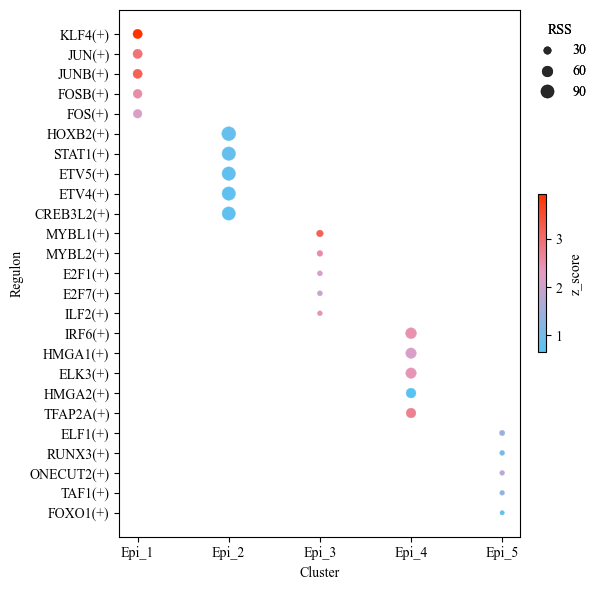

In [149]:
plot_top_regulon(rss_df_large, file_name='Large_top_regulon')

meta NOT subset; don't know how to subset; dropped


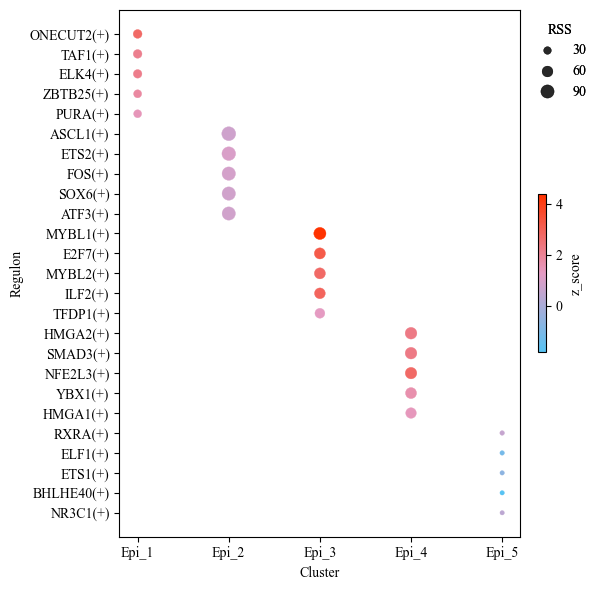

In [150]:
plot_top_regulon(rss_df_small, file_name='Small_top_regulon')

In [135]:
rss_df_ov = rss_df_ov[inter_regulon]
rss_df_ov.head()

,CEBPB(+),PLAGL2(+),ASCL1(+),ETV1(+),MYC(+),POU3F1(+),RFX2(+),MYBL1(+),RUNX3(+),NFE2L3(+),...,ELK3(+),STAT2(+),FOXA1(+),HOXA10(+),SOX13(+),IRF2(+),YY1(+),RFX7(+),ELF1(+),NR2F2(+)
Epi_1,0.276831,0.281196,0.297889,0.324183,0.268495,0.288692,0.325581,0.432861,0.285779,0.314389,...,0.316723,0.292809,0.269089,0.283565,0.306740,0.221620,0.342888,0.246719,0.322881,0.237056
Epi_3,0.477368,0.424564,0.418848,0.608692,0.446893,0.457413,0.567403,0.468241,0.413083,0.537906,...,0.547286,0.445706,0.394738,0.426167,0.452869,0.286341,0.503391,0.375235,0.555058,0.367543
Epi_2,0.280291,0.298872,0.248969,0.285508,0.310233,0.285212,0.248347,0.315295,0.236832,0.282055,...,0.280513,0.263230,0.246603,0.262642,0.250657,0.217513,0.314804,0.228024,0.268061,0.455190


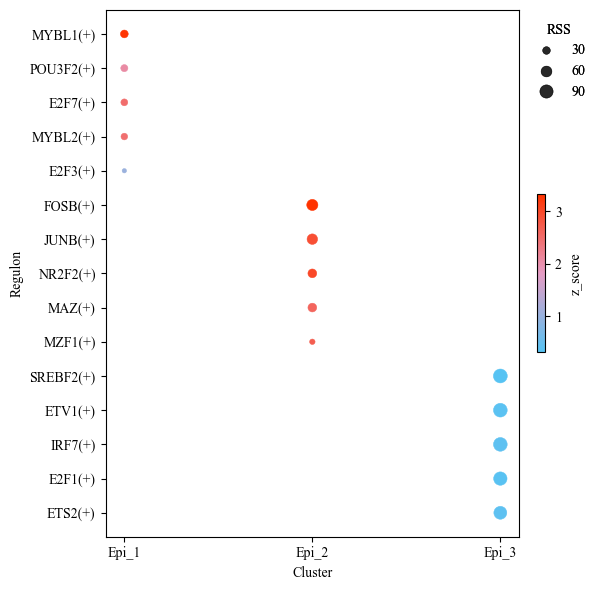

In [136]:
plot_top_regulon(rss_df_ov)

meta NOT subset; don't know how to subset; dropped


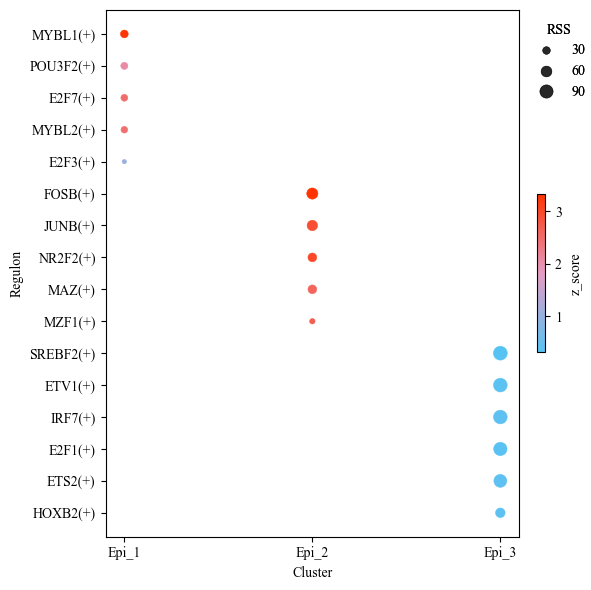

In [148]:
rss_z = zscore(zscore(rss_df_ov, axis=0).dropna(axis=1), axis=1)

rss_melt_df = rss_df_ov.reset_index().melt(id_vars='index', var_name='regulon', value_name='RSS')
rss_z = rss_z.reset_index().melt(id_vars='index', var_name='regulon', value_name='z_score')
rss_melt_df = rss_melt_df.merge(rss_z, on=['index', 'regulon'], how='inner')

top_rss_df = rss_df_ov.stack().reset_index().rename(columns={0:'RSS'}).groupby('level_0').apply(lambda x: x.nlargest(5, 'RSS')).reset_index(drop=True).rename(columns={'level_0': 'index', 'level_1': 'regulon'})
top_rss_df = top_rss_df.merge(rss_z, on=['index', 'regulon'], how='inner')

top_rss_df = pd.concat([top_rss_df, rss_melt_df.loc[rss_melt_df['regulon'] == 'HOXB2(+)', :].iloc[[1]]], ignore_index=True)

import matplotlib as mpl

plt.figure(figsize=(6, 6))

custom_colors = ["#57C3F3", "#E59CC4", "#FF3300"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

scp = sns.scatterplot(data=top_rss_df,
                x='index', y='regulon',
                size='RSS', hue='z_score',
                sizes=(10, 100),  # 最小/最大点大小
                palette=cmap_custom, edgecolor=None)

if scp.legend_ is not None:
    scp.legend_.remove()
scatter_obj = scp.collections[0]

handles, labels = scatter_obj.legend_elements(prop="sizes", num=3, alpha=0.6)
size_legend = plt.legend(
    handles, labels,
    title="RSS",
    bbox_to_anchor=(1, 1),
    loc='upper left',
    frameon=False
)
plt.gca().add_artist(size_legend)

norm = mpl.colors.Normalize(
    vmin=top_rss_df['z_score'].min(),
    vmax=top_rss_df['z_score'].max()
)
sm = plt.cm.ScalarMappable(cmap=cmap_custom, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.05, pad=0.04, shrink=0.3)
cbar.set_label("z_score")


plt.xlabel("Cluster")
plt.ylabel("Regulon")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('./fig/fig4_update_fig3_regulon_top.pdf', format='pdf')
plt.show()

In [140]:
top_rss_df

,index,regulon,RSS,z_score
0,Epi_1,MYBL1(+),0.432861,3.277514
1,Epi_1,POU3F2(+),0.418944,2.060350
2,Epi_1,E2F7(+),0.414502,2.491314
3,Epi_1,MYBL2(+),0.410494,2.455545
4,Epi_1,E2F3(+),0.375718,1.043462
5,Epi_2,FOSB(+),0.520070,3.317562
6,Epi_2,JUNB(+),0.501132,2.901622
7,Epi_2,NR2F2(+),0.455190,3.011400
8,Epi_2,MAZ(+),0.454786,2.595488
9,Epi_2,MZF1(+),0.390254,2.696722


/tmp/ipykernel_78/82722604.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x=condition_name, y=term, data=plot_df, flierprops={'visible': False},
/tmp/ipykernel_78/82722604.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=condition_name, y=term, data=plot_df, order=[pos_con, neg_con], palette=palette_1, size=5, alpha=0.8,
meta NOT subset; don't know how to subset; dropped


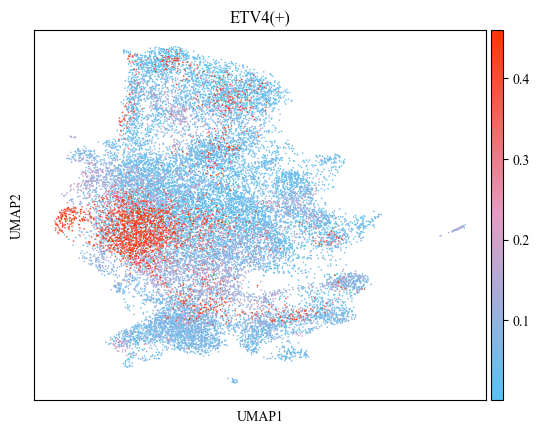

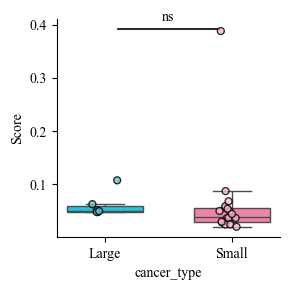

In [153]:
adata.obs['ETV4(+)'] = auc_mtx['ETV4(+)']
sc.pl.umap(adata, color='ETV4(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

tmp_df = adata.obs.groupby(['cancer_type', 'batch'])['ETV4(+)'].median().reset_index().dropna()
plot_significant_box(tmp_df, 'ETV4(+)', condition=['Large', 'Small'])

/tmp/ipykernel_78/82722604.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x=condition_name, y=term, data=plot_df, flierprops={'visible': False},
/tmp/ipykernel_78/82722604.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=condition_name, y=term, data=plot_df, order=[pos_con, neg_con], palette=palette_1, size=5, alpha=0.8,
meta NOT subset; don't know how to subset; dropped


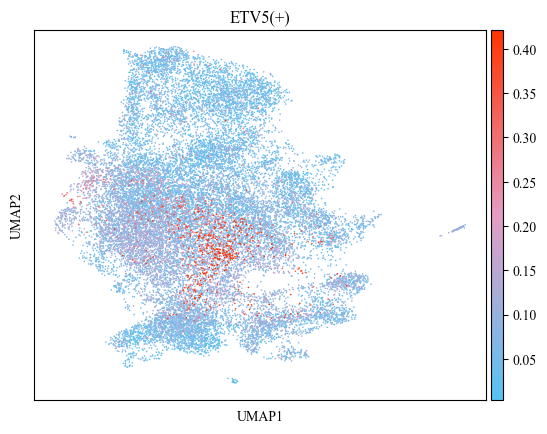

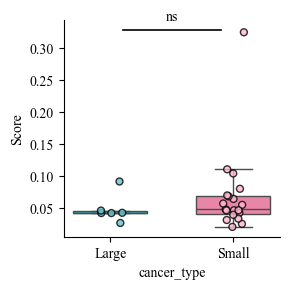

In [154]:
adata.obs['ETV5(+)'] = auc_mtx['ETV5(+)']
sc.pl.umap(adata, color='ETV5(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)

tmp_df = adata.obs.groupby(['cancer_type', 'batch'])['ETV5(+)'].median().reset_index().dropna()
plot_significant_box(tmp_df, 'ETV5(+)', condition=['Large', 'Small'])

meta NOT subset; don't know how to subset; dropped


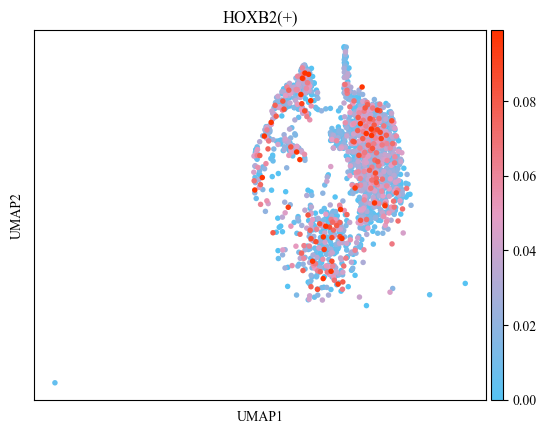

In [159]:
adata_1.obs['HOXB2(+)'] = auc_ov['HOXB2(+)']
sc.pl.umap(adata_1, color='HOXB2(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)
plt.savefig('./fig/fig4_HOXB2_ov_umap.pdf', format='pdf')

meta NOT subset; don't know how to subset; dropped


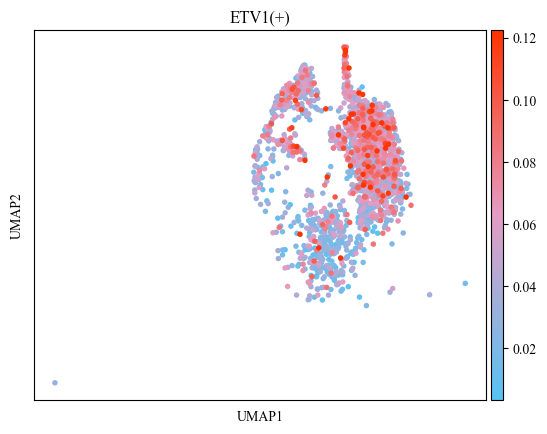

In [160]:
adata_1.obs['ETV1(+)'] = auc_ov['ETV1(+)']
sc.pl.umap(adata_1, color='ETV1(+)', vmax='p99', vmin='p1', cmap=cmap_custom, show=False)
plt.savefig('./fig/fig4_ETV1_ov_umap.pdf', format='pdf')

/opt/software/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
meta NOT subset; don't know how to subset; dropped


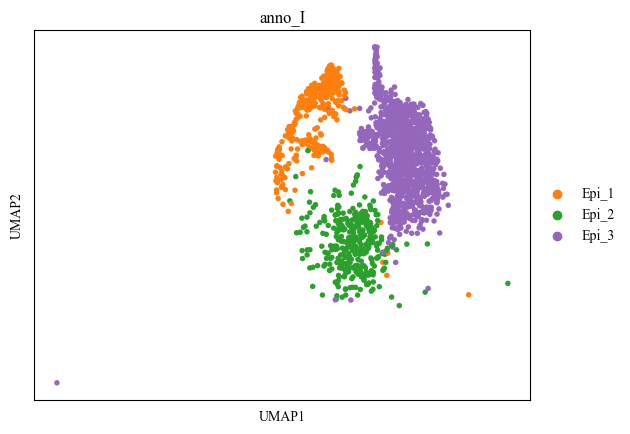

In [161]:
sc.pl.umap(adata_1, color='anno_I', show=False)
plt.savefig('./fig/fig4_anno_umap.pdf', format='pdf')